In [21]:
import pandas as pd
#Load the dataset
df = pd.read_csv("/content/drive/MyDrive/Huntington/Huntington_Disease_Dataset.csv")
df.head()

,Patient_ID,Age,Sex,Family_History,HTT_CAG_Repeat_Length,Motor_Symptoms,Cognitive_Decline,Chorea_Score,Brain_Volume_Loss,Functional_Capacity,...,HTT_Gene_Expression_Level,Protein_Aggregation_Level,Random_Protein_Sequence,Random_Gene_Sequence,Disease_Stage,Gene/Factor,Chromosome_Location,Function,Effect,Category
0,b2a49170-8561-4665-9371-2240b55dd87a,31,Male,No,67,Moderate,Severe,8.80,3.20,94,...,1.67,0.58,DAHKIRSPMRVGPHYYAQCDNNDTGSDKEHWLKTEAAPMTMDRTVE...,GCCAGCAGCGCCCGAGCGTATGAGGTATATGGATTGGACATTGGGC...,Middle,HTT,4p16.3,CAG Trinucleotide Repeat Expansion,Neurodegeneration,Primary Cause
1,f5fae45d-8718-41c4-a957-6928f79f3c8e,33,Female,Yes,38,Severe,Moderate,3.24,5.98,50,...,0.18,0.30,PANGFWYHNCLRFWNIPPYVMEGFPLADITEVHKWRVSGFMCWETQ...,AGTTTTCAGTGAGACTCTTCCCCAAAAGCCTCCACTACGACAGTGT...,Pre-Symptomatic,HTT,4p16.3,CAG Trinucleotide Repeat Expansion,Neurodegeneration,Primary Cause
2,66ab0567-050b-4d56-9ec4-b676309899a6,69,Male,Yes,37,Severe,Moderate,1.01,2.82,69,...,0.90,1.04,NWHEGHGASTWKATMVAWCLMVQHAVTWKEGNTRCREMSCMNFTQL...,TATACCACCAGTGGGAAGAGTAACGATTTTGGAGCGCCCCGAGTCC...,Early,MSH3,5q14.1,Mismatch Repair,CAG Repeat Expansion,Trans-acting Modifier
3,996a48e4-e841-418f-a539-5a7a86cd815d,66,Male,Yes,50,Mild,Severe,3.21,6.77,76,...,1.16,1.87,KCVQYIQATQMLVQSWGQRNPIMQSSEPDRAHDYESGTPKTYTYML...,GCGCGACCGACCAAAGGACCCATGGTGGTGATCTGTCATTGGATTC...,Pre-Symptomatic,MSH3,5q14.1,Mismatch Repair,CAG Repeat Expansion,Trans-acting Modifier
4,d45c7ca8-7125-4aaa-8018-5bbc60d35a1f,43,Female,Yes,48,Moderate,Mild,2.31,7.53,70,...,1.85,2.94,DQPGNMTRQNKNHCMWRAKRPTKHPGHKPGEIDKEKSEQNDADSSA...,GGGACCGCGGTTCTAGAAGAGAGGTTCTCTGACCGCCGAAGGATTC...,Late,HTT (Somatic Expansion),4p16.3,CAG Repeat Instability,Faster Disease Onset,Cis-acting Modifier


In [22]:
#Drop irrelevant columns
df.drop(columns=['Patient_ID', 'Random_Protein_Sequence', 'Random_Gene_Sequence'], inplace=True)

In [23]:
#Check for missing values
print(df.isnull().sum())

Age                              0
Sex                              0
Family_History                   0
HTT_CAG_Repeat_Length            0
Motor_Symptoms                   0
Cognitive_Decline            12119
Chorea_Score                     0
Brain_Volume_Loss                0
Functional_Capacity              0
Gene_Mutation_Type               0
HTT_Gene_Expression_Level        0
Protein_Aggregation_Level        0
Disease_Stage                    0
Gene/Factor                      0
Chromosome_Location              0
Function                         0
Effect                           0
Category                         0
dtype: int64


In [24]:
print(df['Cognitive_Decline'].unique())
print(df['Cognitive_Decline'].value_counts())
print(df['Cognitive_Decline'].dtype)

['Severe' 'Moderate' 'Mild' nan]
Cognitive_Decline
Moderate    12243
Severe      12132
Mild        12042
Name: count, dtype: int64
object


It is considering 'None' entries as nan in the Cognitive_Decline column.

In [25]:
df['Cognitive_Decline'] = df['Cognitive_Decline'].astype(str).str.strip().str.lower()

df['Cognitive_Decline'].replace({'0': 'none', '': 'none', 'nan': 'none'}, inplace=True)

severity_map = {
    'none': 0,
    'mild': 1,
    'moderate': 2,
    'severe': 3
}

df['Cognitive_Decline'] = df['Cognitive_Decline'].map(severity_map)

print(df['Cognitive_Decline'].isna().sum())
print(df['Cognitive_Decline'].unique())

0
[3 2 1 0]


<ipython-input-25-a2d6bdaccd91>:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Cognitive_Decline'].replace({'0': 'none', '': 'none', 'nan': 'none'}, inplace=True)


In [26]:
from sklearn.preprocessing import LabelEncoder, StandardScaler

#Ordinal encoding for symptom severity
ordinal_maps = {
    'Motor_Symptoms': {'None': 0, 'Mild': 1, 'Moderate': 2, 'Severe': 3}
}

for col, mapping in ordinal_maps.items():
    df[col] = df[col].astype(str).str.strip().str.title().map(mapping)

#Label encode nominal categorical features
label_enc_cols = [
    'Sex', 'Family_History', 'Gene_Mutation_Type',
    'Gene/Factor', 'Chromosome_Location', 'Function', 'Effect', 'Category', 'Disease_Stage'
]

label_encoders = {}
for col in label_enc_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].astype(str).str.strip())
    label_encoders[col] = le

#Numerical scaling
num_cols = [
    'Age', 'HTT_CAG_Repeat_Length', 'Chorea_Score',
    'Brain_Volume_Loss', 'Functional_Capacity',
    'HTT_Gene_Expression_Level', 'Protein_Aggregation_Level'
]

scaler = StandardScaler()
df[num_cols] = scaler.fit_transform(df[num_cols])

df.head()

,Age,Sex,Family_History,HTT_CAG_Repeat_Length,Motor_Symptoms,Cognitive_Decline,Chorea_Score,Brain_Volume_Loss,Functional_Capacity,Gene_Mutation_Type,HTT_Gene_Expression_Level,Protein_Aggregation_Level,Disease_Stage,Gene/Factor,Chromosome_Location,Function,Effect,Category
0,-1.630576,1,0,0.714972,2,3,1.313501,-1.100404,1.495241,0,0.533420,-1.390031,2,0,1,1,2,1
1,-1.495093,0,1,-1.471395,3,2,-0.605530,0.383865,-0.012156,3,-1.620850,-1.587949,3,0,1,1,2,1
2,0.943601,1,1,-1.546787,3,2,-1.375213,-1.303289,0.638765,1,-0.579861,-1.064881,0,3,2,2,0,2
3,0.740376,1,1,-0.566692,1,3,-0.615884,0.805654,0.878578,0,-0.203948,-0.478197,3,3,2,2,0,2
4,-0.817678,0,1,-0.717475,2,1,-0.926519,1.211425,0.673024,2,0.793668,0.278131,1,1,1,0,1,0


In [27]:
#Check for missing values again
print(df.isnull().sum())
import pandas as pd

for column in df.columns:
    print(f"Unique values in column '{column}':")
    print(df[column].value_counts())
    print("\n")

Age                          0
Sex                          0
Family_History               0
HTT_CAG_Repeat_Length        0
Motor_Symptoms               0
Cognitive_Decline            0
Chorea_Score                 0
Brain_Volume_Loss            0
Functional_Capacity          0
Gene_Mutation_Type           0
HTT_Gene_Expression_Level    0
Protein_Aggregation_Level    0
Disease_Stage                0
Gene/Factor                  0
Chromosome_Location          0
Function                     0
Effect                       0
Category                     0
dtype: int64
Unique values in column 'Age':
Age
 1.688757    1028
-1.630576    1006
-0.953161    1004
 1.011342    1001
 0.198444     998
-0.546712     994
-0.614454     992
 1.621015     989
 1.079084     983
 0.604893     982
-1.698317     982
 1.350050     973
-0.275746     973
 0.808118     972
 0.469410     971
-1.359610     967
-0.749937     967
-0.411229     963
 1.282308     963
 1.553274     962
 0.537152     961
-1.291869     95

In [28]:
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

X = df.drop(columns=['Disease_Stage'])
y = df['Disease_Stage']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

NAIVE BAYES

Naive Bayes Classification Report:
              precision    recall  f1-score   support

           0       0.27      0.17      0.21      2457
           1       0.25      0.20      0.22      2394
           2       0.26      0.37      0.30      2456
           3       0.24      0.29      0.26      2401

    accuracy                           0.25      9708
   macro avg       0.26      0.25      0.25      9708
weighted avg       0.26      0.25      0.25      9708

Accuracy: 0.2542233209723939


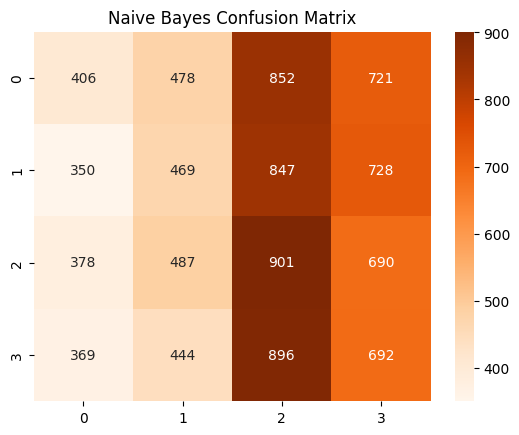

In [29]:
from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB()
gnb.fit(X_train, y_train)
y_pred_gnb = gnb.predict(X_test)

print("Naive Bayes Classification Report:")
print(classification_report(y_test, y_pred_gnb))
print("Accuracy:", accuracy_score(y_test, y_pred_gnb))

sns.heatmap(confusion_matrix(y_test, y_pred_gnb), annot=True, fmt='d', cmap='Oranges')
plt.title("Naive Bayes Confusion Matrix")
plt.show()

Decision Tree

Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       0.26      0.26      0.26      2457
           1       0.23      0.23      0.23      2394
           2       0.26      0.26      0.26      2456
           3       0.25      0.25      0.25      2401

    accuracy                           0.25      9708
   macro avg       0.25      0.25      0.25      9708
weighted avg       0.25      0.25      0.25      9708

Accuracy: 0.2504120313143799


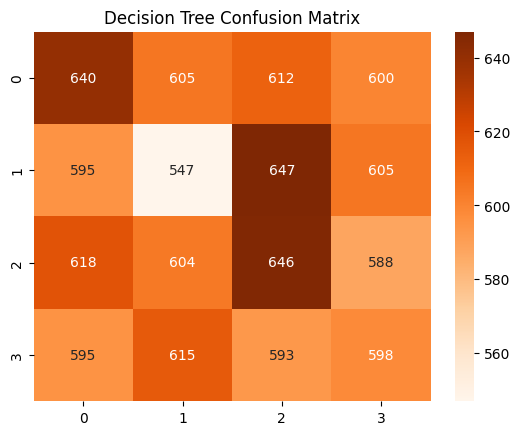

In [30]:
from sklearn.tree import DecisionTreeClassifier

#Fit Decision Tree
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

#Evaluation
print("Decision Tree Classification Report:")
print(classification_report(y_test, y_pred_dt))
print("Accuracy:", accuracy_score(y_test, y_pred_dt))

#Confusion Matrix
sns.heatmap(confusion_matrix(y_test, y_pred_dt), annot=True, fmt='d', cmap='Oranges')
plt.title("Decision Tree Confusion Matrix")
plt.show()

Random Forest

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.26      0.26      0.26      2457
           1       0.26      0.25      0.25      2394
           2       0.25      0.26      0.25      2456
           3       0.26      0.26      0.26      2401

    accuracy                           0.26      9708
   macro avg       0.26      0.26      0.26      9708
weighted avg       0.26      0.26      0.26      9708

Accuracy: 0.257622579316028


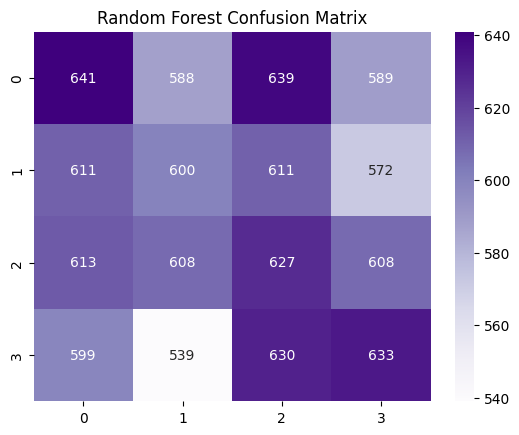

In [31]:
from sklearn.ensemble import RandomForestClassifier

#Fit Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

#Evaluation
print("Random Forest Classification Report:")
print(classification_report(y_test, y_pred_rf))
print("Accuracy:", accuracy_score(y_test, y_pred_rf))

#Confusion Matrix
sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', cmap='Purples')
plt.title("Random Forest Confusion Matrix")
plt.show()

GRADIENT BOOSTING

Gradient Boosting Classification Report:
              precision    recall  f1-score   support

           0       0.25      0.18      0.21      2457
           1       0.25      0.22      0.23      2394
           2       0.26      0.30      0.28      2456
           3       0.24      0.30      0.27      2401

    accuracy                           0.25      9708
   macro avg       0.25      0.25      0.25      9708
weighted avg       0.25      0.25      0.25      9708

Accuracy: 0.2481458590852905


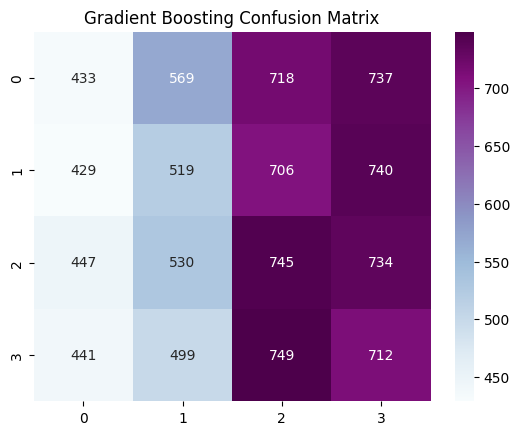

In [76]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(random_state=42)
gb.fit(X_train, y_train)
y_pred_gb= gb.predict(X_test)

print("Gradient Boosting Classification Report:")
print(classification_report(y_test, y_pred_gb))
print("Accuracy:", accuracy_score(y_test, y_pred_gb))
sns.heatmap(confusion_matrix(y_test, y_pred_gb), annot=True, fmt='d', cmap='BuPu')
plt.title("Gradient Boosting Confusion Matrix")
plt.show()

In [32]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

#Fit on training data and transform both train and test for KNN, SVM, LOGISTIC REGRESSION, KMEANS
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

SVM

SVM Classification Report:
              precision    recall  f1-score   support

           0       0.26      0.20      0.22      2457
           1       0.26      0.23      0.24      2394
           2       0.26      0.28      0.27      2456
           3       0.25      0.32      0.28      2401

    accuracy                           0.26      9708
   macro avg       0.26      0.26      0.25      9708
weighted avg       0.26      0.26      0.25      9708

Accuracy: 0.25628347754429337


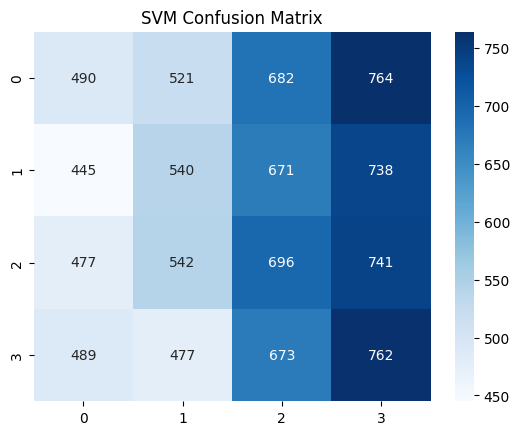

In [35]:
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

#Fit SVM
svm = SVC(kernel='rbf', random_state=42)
svm.fit(X_train_scaled, y_train)
y_pred_svm = svm.predict(X_test_scaled)

#Evaluation
print("SVM Classification Report:")
print(classification_report(y_test, y_pred_svm))
print("Accuracy:", accuracy_score(y_test, y_pred_svm))

#Confusion Matrix
sns.heatmap(confusion_matrix(y_test, y_pred_svm), annot=True, fmt='d', cmap='Blues')
plt.title("SVM Confusion Matrix")
plt.show()

Logistic Regression

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.28      0.20      0.23      2457
           1       0.25      0.17      0.20      2394
           2       0.26      0.30      0.28      2456
           3       0.25      0.36      0.30      2401

    accuracy                           0.26      9708
   macro avg       0.26      0.26      0.25      9708
weighted avg       0.26      0.26      0.25      9708

Accuracy: 0.257622579316028


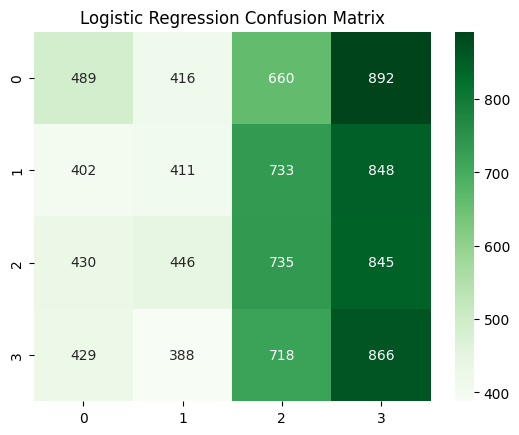

In [36]:
from sklearn.linear_model import LogisticRegression

#Fit Logistic Regression
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_scaled, y_train)
y_pred_lr = lr.predict(X_test_scaled)

#Evaluation
print("Logistic Regression Classification Report:")
print(classification_report(y_test, y_pred_lr))
print("Accuracy:", accuracy_score(y_test, y_pred_lr))

#Confusion Matrix
sns.heatmap(confusion_matrix(y_test, y_pred_lr), annot=True, fmt='d', cmap='Greens')
plt.title("Logistic Regression Confusion Matrix")
plt.show()

K-MEANS CLUSTERING

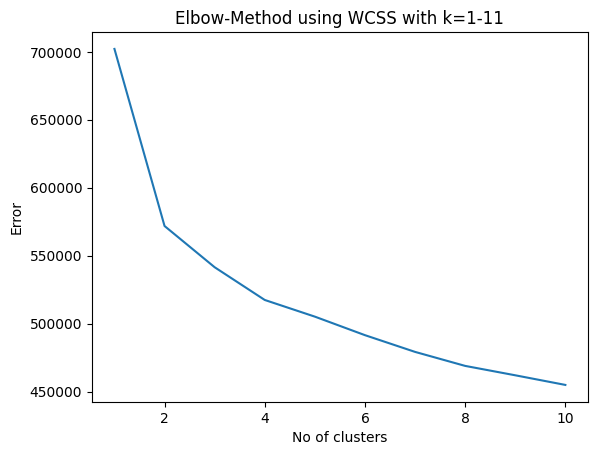

In [15]:
from sklearn.cluster import KMeans

Error =[]
for i in range(1, 11):
    kmeans = KMeans(n_clusters = i, max_iter = 300, n_init = 10, random_state = 0).fit(X)
    Error.append(kmeans.inertia_)
import matplotlib.pyplot as plt
plt.plot(range(1, 11), Error)
plt.title('Elbow-Method using WCSS with k=1-11')
plt.xlabel('No of clusters')
plt.ylabel('Error') #within cluster sum of squares
plt.show()

KMeans Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00      2457
           1       0.00      0.00      0.00      2394
           2       0.25      0.75      0.38      2456
           3       0.24      0.25      0.25      2401

    accuracy                           0.25      9708
   macro avg       0.12      0.25      0.16      9708
weighted avg       0.12      0.25      0.16      9708

Accuracy: 0.25103007828594975


/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


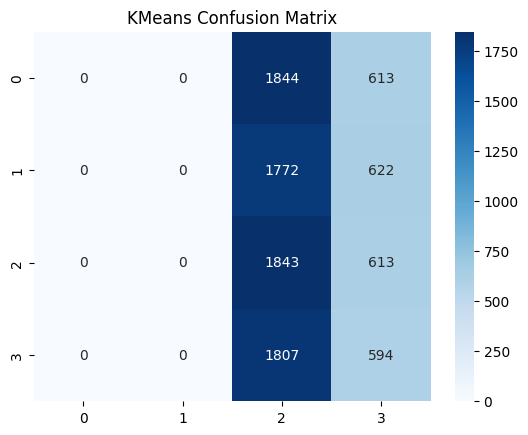

In [33]:
from sklearn.cluster import KMeans
from scipy.stats import mode

#Fit KMeans
kmeans = KMeans(n_clusters=len(np.unique(y)), random_state=42)
kmeans.fit(X_train_scaled)

#Align cluster labels with true labels
labels_map = {}
for i in range(len(np.unique(y))):
    cluster_indices = (kmeans.labels_ == i)
    most_common = mode(y_train[cluster_indices], keepdims=True).mode[0]
    labels_map[i] = most_common

#Predict
kmeans_labels = [labels_map[label] for label in kmeans.predict(X_test_scaled)]

#Evaluation
print("KMeans Classification Report:")
print(classification_report(y_test, kmeans_labels))
print("Accuracy:", accuracy_score(y_test, kmeans_labels))

#Confusion Matrix
sns.heatmap(confusion_matrix(y_test, kmeans_labels), annot=True, fmt='d', cmap='Blues')
plt.title("KMeans Confusion Matrix")
plt.show()

K-Nearest Neighbours

KNN Classification Report:
              precision    recall  f1-score   support

           0       0.26      0.34      0.30      2457
           1       0.25      0.28      0.26      2394
           2       0.26      0.23      0.24      2456
           3       0.25      0.17      0.20      2401

    accuracy                           0.26      9708
   macro avg       0.25      0.25      0.25      9708
weighted avg       0.25      0.26      0.25      9708

Accuracy: 0.25515039142974866


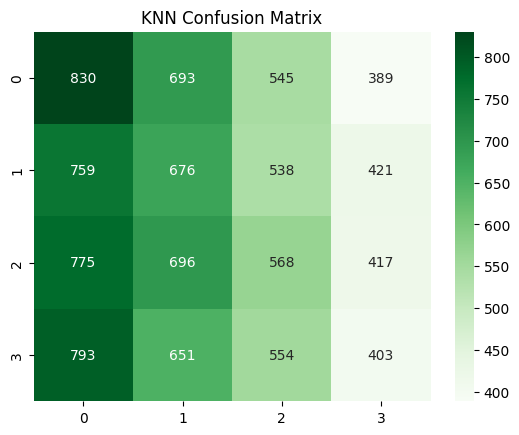

In [34]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
y_pred_knn = knn.predict(X_test_scaled)

print("KNN Classification Report:")
print(classification_report(y_test, y_pred_knn))
print("Accuracy:", accuracy_score(y_test, y_pred_knn))

sns.heatmap(confusion_matrix(y_test, y_pred_knn), annot=True, fmt='d', cmap='Greens')
plt.title("KNN Confusion Matrix")
plt.show()

Feature selection using Variance Threshold

In [78]:
from sklearn.feature_selection import VarianceThreshold
var_thresh = VarianceThreshold(threshold=0.05)
var_thresh.fit(df)

print(var_thresh.get_feature_names_out())
print(len(var_thresh.get_feature_names_out()))
print(var_thresh.get_support())
print(len(var_thresh.get_support()))

const_col = [col for col in df.columns
             if col not in df.columns[var_thresh.get_support()]]

print(len(const_col))

for feature in const_col :
  print(feature)

['Age' 'Sex' 'Family_History' 'HTT_CAG_Repeat_Length' 'Motor_Symptoms'
 'Cognitive_Decline' 'Chorea_Score' 'Brain_Volume_Loss'
 'Functional_Capacity' 'Gene_Mutation_Type' 'HTT_Gene_Expression_Level'
 'Protein_Aggregation_Level' 'Disease_Stage' 'Gene/Factor'
 'Chromosome_Location' 'Function' 'Effect' 'Category']
18
[ True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True]
18
0


Feature Selection using correlation

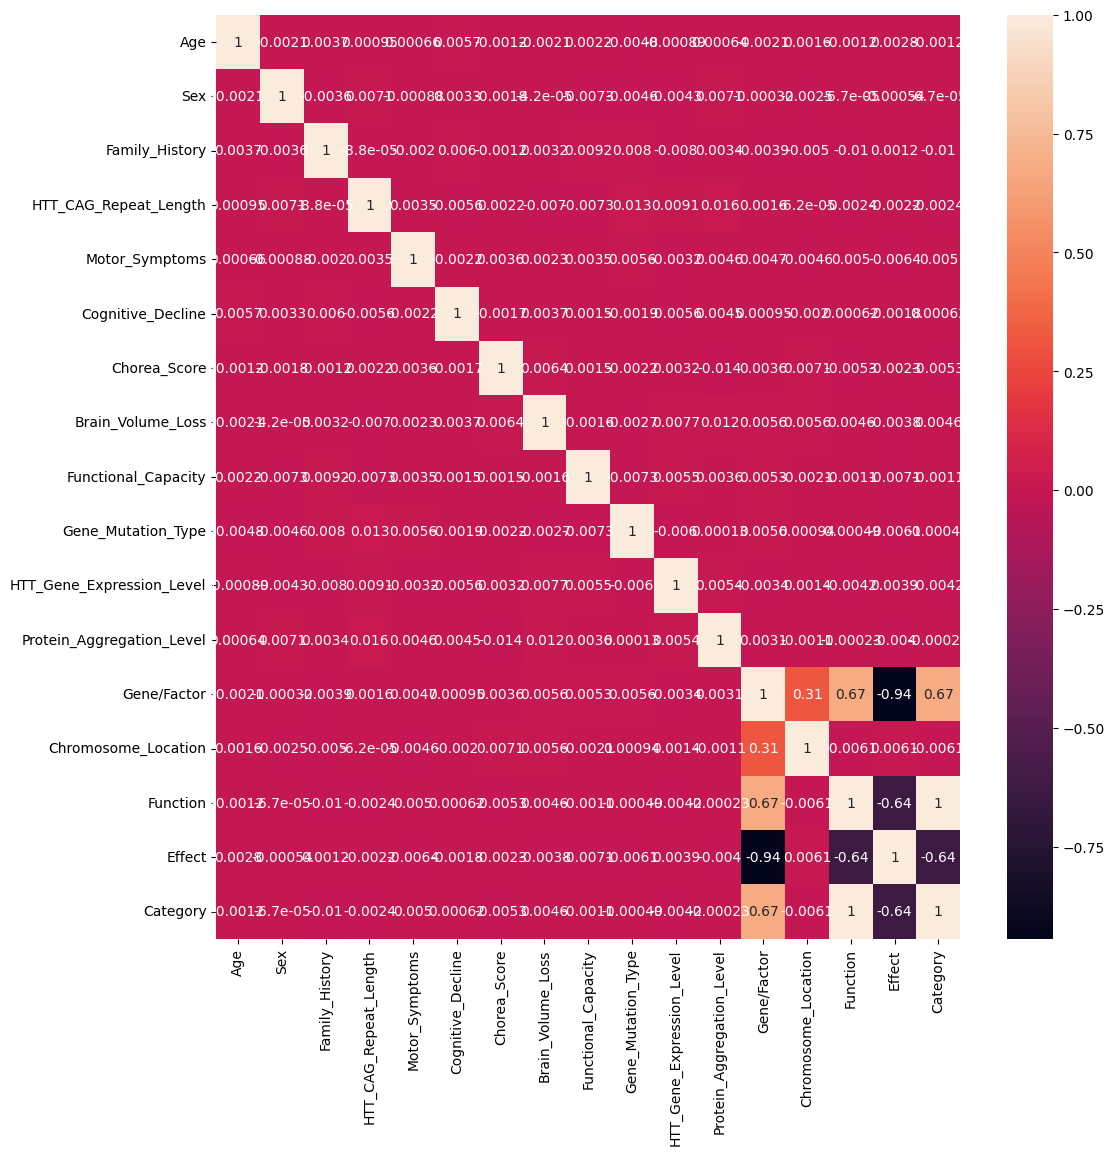

In [79]:
plt.figure(figsize=(12,12))
correlation_mat = X_train.corr()
sns.heatmap(correlation_mat, annot=True)
plt.show()

In [80]:
def correlation(dataset, threshold):
  col_corr = set()
  corr_mat = dataset.corr()
  for i in range(len(corr_mat.columns)):
    for j in range(i):
      if abs(corr_mat.iloc[i, j]) > threshold:
        colname = corr_mat.columns[i]
        col_corr.add(colname)
  return col_corr

In [81]:
corr_features = correlation(X_train, 0.85)
len(set(corr_features))
print(corr_features)

df_new = df.drop(corr_features, axis=1)
df_new.head()

{'Effect', 'Category'}


,Age,Sex,Family_History,HTT_CAG_Repeat_Length,Motor_Symptoms,Cognitive_Decline,Chorea_Score,Brain_Volume_Loss,Functional_Capacity,Gene_Mutation_Type,HTT_Gene_Expression_Level,Protein_Aggregation_Level,Disease_Stage,Gene/Factor,Chromosome_Location,Function
0,-1.630576,1,0,0.714972,2,3,1.313501,-1.100404,1.495241,0,0.533420,-1.390031,2,0,1,1
1,-1.495093,0,1,-1.471395,3,2,-0.605530,0.383865,-0.012156,3,-1.620850,-1.587949,3,0,1,1
2,0.943601,1,1,-1.546787,3,2,-1.375213,-1.303289,0.638765,1,-0.579861,-1.064881,0,3,2,2
3,0.740376,1,1,-0.566692,1,3,-0.615884,0.805654,0.878578,0,-0.203948,-0.478197,3,3,2,2
4,-0.817678,0,1,-0.717475,2,1,-0.926519,1.211425,0.673024,2,0.793668,0.278131,1,1,1,0


MODEL IMPLEMENTATION AFTER FEATURE SELECTION

In [82]:
X_new = df_new.drop(columns=['Disease_Stage'])
y_new = df_new['Disease_Stage']

X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(X_new, y_new, test_size=0.2, random_state=42)

NAIVE BAYES

Naive Bayes Classification Report:
              precision    recall  f1-score   support

           0       0.27      0.17      0.21      2457
           1       0.25      0.19      0.22      2394
           2       0.26      0.33      0.29      2456
           3       0.25      0.33      0.28      2401

    accuracy                           0.26      9708
   macro avg       0.26      0.26      0.25      9708
weighted avg       0.26      0.26      0.25      9708

Accuracy: 0.2554594149155336


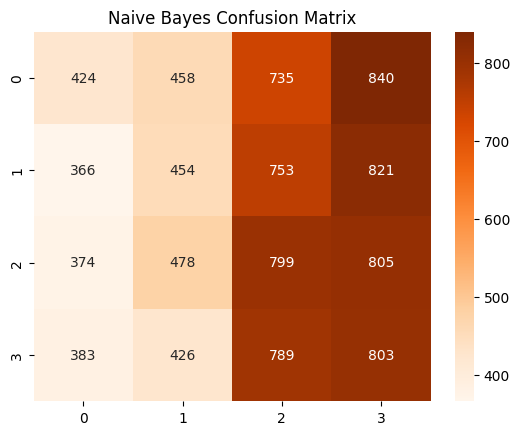

In [83]:
gnb_new = GaussianNB()
gnb_new.fit(X_train_new, y_train_new)
y_pred_gnb_new = gnb_new.predict(X_test_new)

print("Naive Bayes Classification Report:")
print(classification_report(y_test_new, y_pred_gnb_new))
print("Accuracy:", accuracy_score(y_test_new, y_pred_gnb_new))

sns.heatmap(confusion_matrix(y_test_new, y_pred_gnb_new), annot=True, fmt='d', cmap='Oranges')
plt.title("Naive Bayes Confusion Matrix")
plt.show()

DECISION TREE

Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       0.25      0.25      0.25      2457
           1       0.23      0.23      0.23      2394
           2       0.26      0.27      0.27      2456
           3       0.25      0.25      0.25      2401

    accuracy                           0.25      9708
   macro avg       0.25      0.25      0.25      9708
weighted avg       0.25      0.25      0.25      9708

Accuracy: 0.24917593737124022


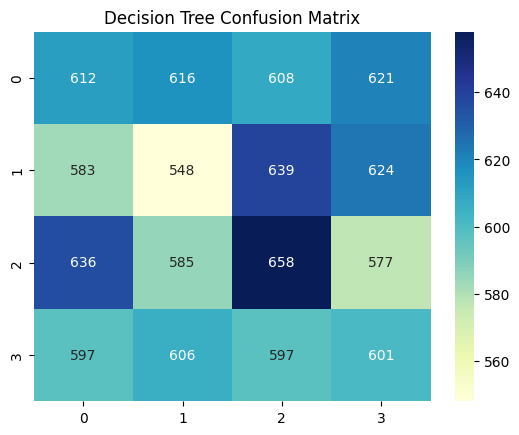

In [84]:
dt_new = DecisionTreeClassifier(random_state=42)
dt_new.fit(X_train_new, y_train_new)
y_pred_dt_new = dt_new.predict(X_test_new)

print("Decision Tree Classification Report:")
print(classification_report(y_test_new, y_pred_dt_new))
print("Accuracy:", accuracy_score(y_test_new, y_pred_dt_new))

sns.heatmap(confusion_matrix(y_test_new, y_pred_dt_new), annot=True, fmt='d', cmap='YlGnBu')
plt.title("Decision Tree Confusion Matrix")
plt.show()

RANDOM FOREST

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.25      0.24      0.24      2457
           1       0.25      0.25      0.25      2394
           2       0.24      0.25      0.25      2456
           3       0.24      0.24      0.24      2401

    accuracy                           0.25      9708
   macro avg       0.25      0.25      0.25      9708
weighted avg       0.25      0.25      0.25      9708

Accuracy: 0.24598269468479605


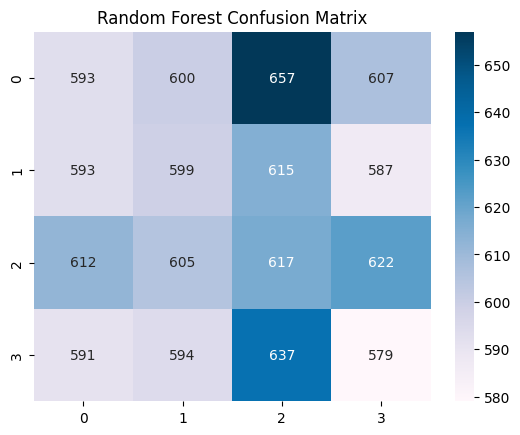

In [85]:
rf_new = RandomForestClassifier(n_estimators=100, random_state=42)
rf_new.fit(X_train_new, y_train_new)
y_pred_rf_new = rf_new.predict(X_test_new)

print("Random Forest Classification Report:")
print(classification_report(y_test_new, y_pred_rf_new))
print("Accuracy:", accuracy_score(y_test_new, y_pred_rf_new))

sns.heatmap(confusion_matrix(y_test_new, y_pred_rf_new), annot=True, fmt='d', cmap='PuBu')
plt.title("Random Forest Confusion Matrix")
plt.show()

GRADIENT BOOSTING

Gradient Boosting Classification Report:
              precision    recall  f1-score   support

           0       0.25      0.18      0.21      2457
           1       0.25      0.22      0.23      2394
           2       0.26      0.30      0.28      2456
           3       0.24      0.30      0.27      2401

    accuracy                           0.25      9708
   macro avg       0.25      0.25      0.25      9708
weighted avg       0.25      0.25      0.25      9708

Accuracy: 0.24824886691388545


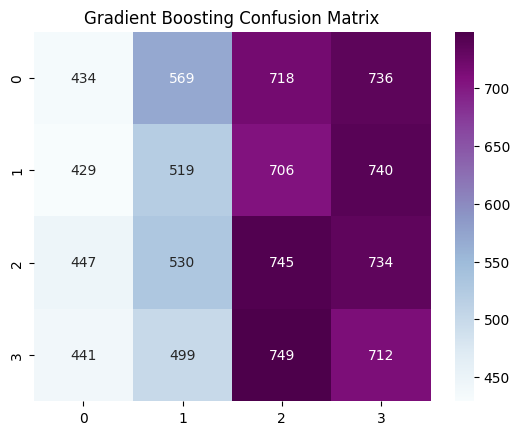

In [86]:
gb_new = GradientBoostingClassifier(random_state=42)
gb_new.fit(X_train_new, y_train_new)
y_pred_gb_new = gb_new.predict(X_test_new)

print("Gradient Boosting Classification Report:")
print(classification_report(y_test_new, y_pred_gb_new))
print("Accuracy:", accuracy_score(y_test_new, y_pred_gb_new))
sns.heatmap(confusion_matrix(y_test_new, y_pred_gb_new), annot=True, fmt='d', cmap='BuPu')
plt.title("Gradient Boosting Confusion Matrix")
plt.show()

In [87]:
scaler_new = StandardScaler()
X_train_new_scaled = scaler_new.fit_transform(X_train_new)
X_test_new_scaled = scaler_new.transform(X_test_new)

LOGISTIC REGRESSION

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.28      0.20      0.23      2457
           1       0.25      0.17      0.20      2394
           2       0.26      0.30      0.28      2456
           3       0.25      0.36      0.30      2401

    accuracy                           0.26      9708
   macro avg       0.26      0.26      0.25      9708
weighted avg       0.26      0.26      0.25      9708

Accuracy: 0.25793160280181293


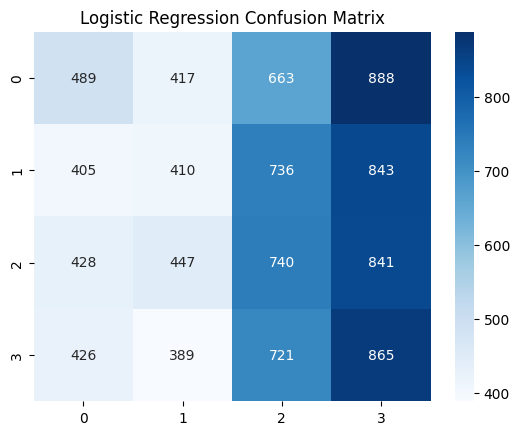

In [88]:
lr_new = LogisticRegression(max_iter=1000, random_state=42)
lr_new.fit(X_train_new_scaled, y_train_new)
y_pred_lr_new = lr_new.predict(X_test_new_scaled)

print("Logistic Regression Classification Report:")
print(classification_report(y_test_new, y_pred_lr_new))
print("Accuracy:", accuracy_score(y_test_new, y_pred_lr_new))

sns.heatmap(confusion_matrix(y_test_new, y_pred_lr_new), annot=True, fmt='d', cmap='Blues')
plt.title("Logistic Regression Confusion Matrix")
plt.show()

SVM

SVM Classification Report:
              precision    recall  f1-score   support

           0       0.25      0.20      0.22      2457
           1       0.26      0.22      0.24      2394
           2       0.26      0.28      0.27      2456
           3       0.25      0.30      0.27      2401

    accuracy                           0.25      9708
   macro avg       0.25      0.25      0.25      9708
weighted avg       0.25      0.25      0.25      9708

Accuracy: 0.25319324268644416


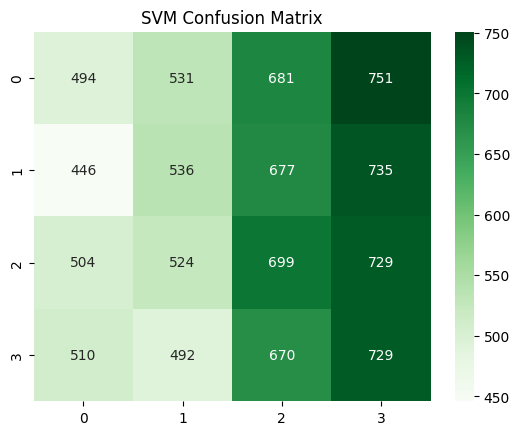

In [89]:
svm_new = SVC(kernel='rbf', random_state=42)
svm_new.fit(X_train_new_scaled, y_train_new)
y_pred_svm_new = svm_new.predict(X_test_new_scaled)

print("SVM Classification Report:")
print(classification_report(y_test_new, y_pred_svm_new))
print("Accuracy:", accuracy_score(y_test_new, y_pred_svm_new))

sns.heatmap(confusion_matrix(y_test_new, y_pred_svm_new), annot=True, fmt='d', cmap='Greens')
plt.title("SVM Confusion Matrix")
plt.show()

KNN

KNN Classification Report:
              precision    recall  f1-score   support

           0       0.26      0.33      0.29      2457
           1       0.25      0.28      0.27      2394
           2       0.26      0.23      0.25      2456
           3       0.25      0.17      0.20      2401

    accuracy                           0.25      9708
   macro avg       0.25      0.25      0.25      9708
weighted avg       0.25      0.25      0.25      9708

Accuracy: 0.2548413679439637


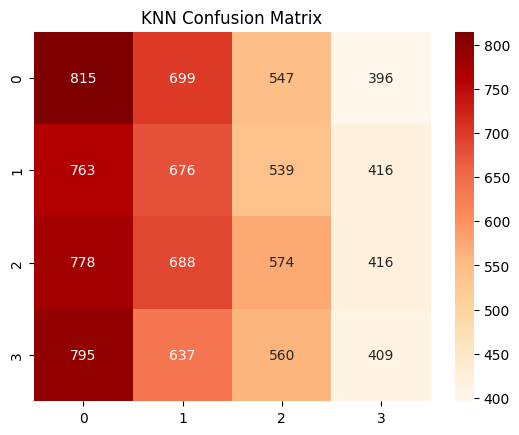

In [90]:
knn_new = KNeighborsClassifier(n_neighbors=5)
knn_new.fit(X_train_new_scaled, y_train_new)
y_pred_knn_new = knn_new.predict(X_test_new_scaled)

print("KNN Classification Report:")
print(classification_report(y_test_new, y_pred_knn_new))
print("Accuracy:", accuracy_score(y_test_new, y_pred_knn_new))

sns.heatmap(confusion_matrix(y_test_new, y_pred_knn_new), annot=True, fmt='d', cmap='OrRd')
plt.title("KNN Confusion Matrix")
plt.show()

KMEANS

KMeans Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00      2457
           1       0.00      0.00      0.00      2394
           2       0.25      0.75      0.38      2456
           3       0.26      0.26      0.26      2401

    accuracy                           0.25      9708
   macro avg       0.13      0.25      0.16      9708
weighted avg       0.13      0.25      0.16      9708

Accuracy: 0.25360527400082405


/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


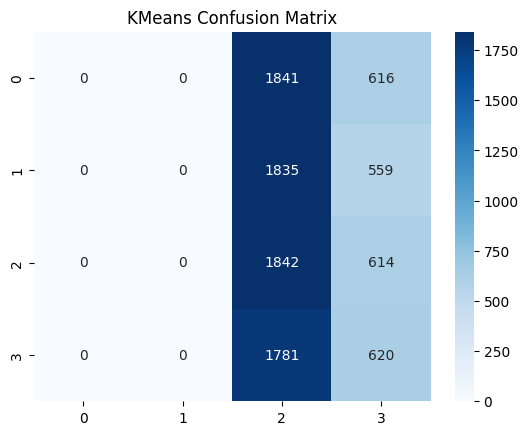

In [91]:
#Fit KMeans
kmeans_new = KMeans(n_clusters=len(y_new.unique()), random_state=42, n_init=10)
kmeans_new.fit(X_train_new_scaled)
y_pred_kmeans_new = kmeans_new.predict(X_test_new_scaled)

#Align cluster labels with true labels
labels_map = {}
for i in range(len(np.unique(y_new))):
    cluster_indices = (kmeans.labels_ == i)
    most_common = mode(y_train_new[cluster_indices], keepdims=True).mode[0]
    labels_map[i] = most_common

#Predict
kmeans_labels = [labels_map[label] for label in kmeans_new.predict(X_test_new_scaled)]

#Evaluation
print("KMeans Classification Report:")
print(classification_report(y_test_new, kmeans_labels))
print("Accuracy:", accuracy_score(y_test_new, kmeans_labels))

#Confusion Matrix
sns.heatmap(confusion_matrix(y_test_new, kmeans_labels), annot=True, fmt='d', cmap='Blues')
plt.title("KMeans Confusion Matrix")
plt.show()

In [57]:
#Define categorical features
categorical_features = [
    'Sex', 'Family_History', 'Motor_Symptoms', 'Cognitive_Decline',
    'Gene_Mutation_Type', 'Gene/Factor', 'Chromosome_Location',
    'Function', 'Effect', 'Category'
]

#All other features are considered numerical
numerical_features = [col for col in df.columns
                      if col not in categorical_features + ['Disease_Stage']]

Chi-square test for categorical features

In [58]:
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.preprocessing import MinMaxScaler

X_cat = df[categorical_features]
y = df['Disease_Stage']

#Scale to non-negative for chi2
scaler = MinMaxScaler()
X_cat_scaled = scaler.fit_transform(X_cat)

chi2_selector = SelectKBest(score_func=chi2, k='all')
chi2_selector.fit(X_cat_scaled, y)

#Combine scores with feature names
chi2_scores = pd.DataFrame({
    'Feature': X_cat.columns,
    'Chi2 Score': chi2_selector.scores_
})
chi2_scores = chi2_scores.sort_values(by='Chi2 Score', ascending=False)
print("Chi-squared Test Scores:\n", chi2_scores)

Chi-squared Test Scores:
                Feature  Chi2 Score
1       Family_History    4.739131
4   Gene_Mutation_Type    1.838207
3    Cognitive_Decline    1.529657
9             Category    1.087005
7             Function    1.087005
0                  Sex    1.061497
8               Effect    0.844298
2       Motor_Symptoms    0.696346
5          Gene/Factor    0.539242
6  Chromosome_Location    0.353607


Dropping features with low Chi2 Score

In [60]:
#List of categorical features with weak association based on Chi2 score
weak_categorical_features = [
    'Sex',
    'Effect',
    'Motor_Symptoms',
    'Gene/Factor',
    'Chromosome_Location'
]

df_chi2 = df.drop(columns=weak_categorical_features)

print("Updated DataFrame shape:", df_chi2.shape)
df_chi2.head()

Updated DataFrame shape: (48536, 13)


,Age,Family_History,HTT_CAG_Repeat_Length,Cognitive_Decline,Chorea_Score,Brain_Volume_Loss,Functional_Capacity,Gene_Mutation_Type,HTT_Gene_Expression_Level,Protein_Aggregation_Level,Disease_Stage,Function,Category
0,-1.630576,0,0.714972,3,1.313501,-1.100404,1.495241,0,0.533420,-1.390031,2,1,1
1,-1.495093,1,-1.471395,2,-0.605530,0.383865,-0.012156,3,-1.620850,-1.587949,3,1,1
2,0.943601,1,-1.546787,2,-1.375213,-1.303289,0.638765,1,-0.579861,-1.064881,0,2,2
3,0.740376,1,-0.566692,3,-0.615884,0.805654,0.878578,0,-0.203948,-0.478197,3,2,2
4,-0.817678,1,-0.717475,1,-0.926519,1.211425,0.673024,2,0.793668,0.278131,1,0,0


ANOVA for numerical features

In [59]:
from sklearn.feature_selection import f_classif

X_num = df[numerical_features]

X_num_scaled = scaler.fit_transform(X_num)

anova_selector = SelectKBest(score_func=f_classif, k='all')
anova_selector.fit(X_num_scaled, y)

anova_scores = pd.DataFrame({
    'Feature': X_num.columns,
    'F Score': anova_selector.scores_
})
anova_scores = anova_scores.sort_values(by='F Score', ascending=False)
print("ANOVA F-test Scores:\n", anova_scores)

ANOVA F-test Scores:
                      Feature   F Score
6  Protein_Aggregation_Level  2.789878
1      HTT_CAG_Repeat_Length  2.636074
3          Brain_Volume_Loss  2.097959
4        Functional_Capacity  1.117649
0                        Age  1.096190
2               Chorea_Score  0.700453
5  HTT_Gene_Expression_Level  0.403625


Dropping features low F Score

In [61]:
#List of numerical features with weak association based on ANOVA F-test
weak_numerical_features = [
    'Chorea_Score',
    'HTT_Gene_Expression_Level'
]

df_final = df_chi2.drop(columns=weak_numerical_features)

print("Final DataFrame shape:", df_final.shape)
df_final.head()

Final DataFrame shape: (48536, 11)


,Age,Family_History,HTT_CAG_Repeat_Length,Cognitive_Decline,Brain_Volume_Loss,Functional_Capacity,Gene_Mutation_Type,Protein_Aggregation_Level,Disease_Stage,Function,Category
0,-1.630576,0,0.714972,3,-1.100404,1.495241,0,-1.390031,2,1,1
1,-1.495093,1,-1.471395,2,0.383865,-0.012156,3,-1.587949,3,1,1
2,0.943601,1,-1.546787,2,-1.303289,0.638765,1,-1.064881,0,2,2
3,0.740376,1,-0.566692,3,0.805654,0.878578,0,-0.478197,3,2,2
4,-0.817678,1,-0.717475,1,1.211425,0.673024,2,0.278131,1,0,0


MODEL IMPLEMENTATION AFTER CHI2 AND ANOVA

In [64]:
X_final = df_final.drop(columns=['Disease_Stage'])
y_final = df_final['Disease_Stage']

X_train_final, X_test_final, y_train_final, y_test_final = train_test_split(
    X_final, y_final, test_size=0.2, random_state=42)

NAIVE BAYES

Naive Bayes Classification Report:
              precision    recall  f1-score   support

           0       0.26      0.17      0.21      2457
           1       0.25      0.17      0.20      2394
           2       0.26      0.37      0.30      2456
           3       0.25      0.30      0.27      2401

    accuracy                           0.25      9708
   macro avg       0.26      0.25      0.25      9708
weighted avg       0.26      0.25      0.25      9708

Accuracy: 0.25473836011536877


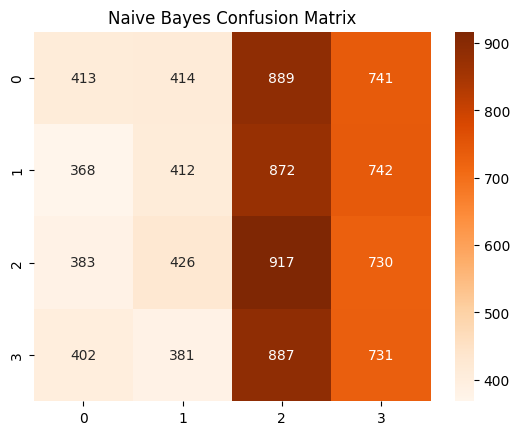

In [65]:
nb_final = GaussianNB()
nb_final.fit(X_train_final, y_train_final)
y_pred_nb = nb_final.predict(X_test_final)

print("Naive Bayes Classification Report:")
print(classification_report(y_test_final, y_pred_nb))
print("Accuracy:", accuracy_score(y_test_final, y_pred_nb))
sns.heatmap(confusion_matrix(y_test_final, y_pred_nb), annot=True, fmt='d', cmap='Oranges')
plt.title("Naive Bayes Confusion Matrix")
plt.show()

RANDOM FOREST

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.26      0.26      0.26      2457
           1       0.26      0.25      0.26      2394
           2       0.25      0.25      0.25      2456
           3       0.25      0.25      0.25      2401

    accuracy                           0.25      9708
   macro avg       0.25      0.25      0.25      9708
weighted avg       0.25      0.25      0.25      9708

Accuracy: 0.25185414091470953


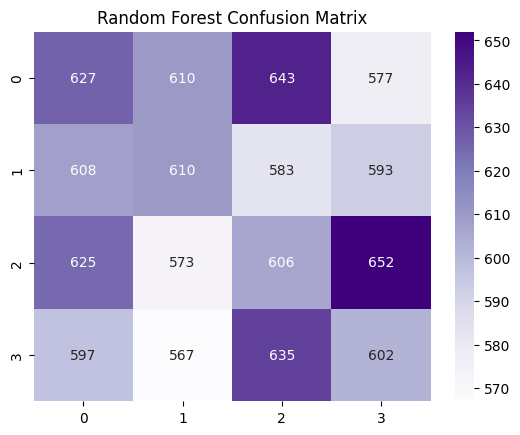

In [66]:
rf_final = RandomForestClassifier(n_estimators=100, random_state=42)
rf_final.fit(X_train_final, y_train_final)
y_pred_rf = rf_final.predict(X_test_final)

print("Random Forest Classification Report:")
print(classification_report(y_test_final, y_pred_rf))
print("Accuracy:", accuracy_score(y_test_final, y_pred_rf))
sns.heatmap(confusion_matrix(y_test_final, y_pred_rf), annot=True, fmt='d', cmap='Purples')
plt.title("Random Forest Confusion Matrix")
plt.show()

DECISION TREE

Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       0.26      0.26      0.26      2457
           1       0.25      0.25      0.25      2394
           2       0.26      0.25      0.26      2456
           3       0.25      0.25      0.25      2401

    accuracy                           0.26      9708
   macro avg       0.26      0.26      0.26      9708
weighted avg       0.26      0.26      0.26      9708

Accuracy: 0.2558714462299135


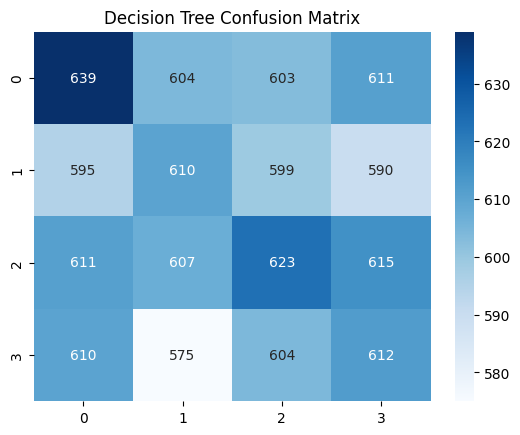

In [67]:
dt_final = DecisionTreeClassifier(random_state=42)
dt_final.fit(X_train_final, y_train_final)
y_pred_dt = dt_final.predict(X_test_final)

print("Decision Tree Classification Report:")
print(classification_report(y_test_final, y_pred_dt))
print("Accuracy:", accuracy_score(y_test_final, y_pred_dt))
sns.heatmap(confusion_matrix(y_test_final, y_pred_dt), annot=True, fmt='d', cmap='Blues')
plt.title("Decision Tree Confusion Matrix")
plt.show()

GRADIENT BOOSTING

Gradient Boosting Classification Report:
              precision    recall  f1-score   support

           0       0.25      0.18      0.21      2457
           1       0.25      0.19      0.22      2394
           2       0.25      0.31      0.28      2456
           3       0.24      0.30      0.27      2401

    accuracy                           0.25      9708
   macro avg       0.25      0.25      0.24      9708
weighted avg       0.25      0.25      0.24      9708

Accuracy: 0.246188710341986


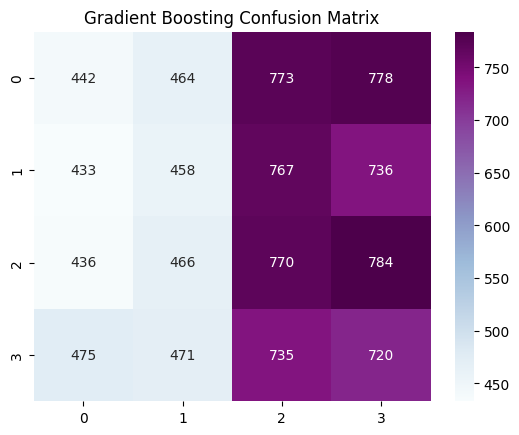

In [74]:
gb_final = GradientBoostingClassifier(random_state=42)
gb_final.fit(X_train_final, y_train_final)
y_pred_gb_final = gb_final.predict(X_test_final)

print("Gradient Boosting Classification Report:")
print(classification_report(y_test_final, y_pred_gb_final))
print("Accuracy:", accuracy_score(y_test_final, y_pred_gb_final))
sns.heatmap(confusion_matrix(y_test_final, y_pred_gb_final), annot=True, fmt='d', cmap='BuPu')
plt.title("Gradient Boosting Confusion Matrix")
plt.show()

In [69]:
scaler = StandardScaler()
X_train_final_scaled = scaler.fit_transform(X_train_final)
X_test_final_scaled = scaler.transform(X_test_final)

LOGISTIC REGRESSION

/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.26      0.79      0.39      2457
           1       0.26      0.03      0.05      2394
           2       0.26      0.20      0.22      2456
           3       0.19      0.02      0.03      2401

    accuracy                           0.26      9708
   macro avg       0.24      0.26      0.17      9708
weighted avg       0.24      0.26      0.18      9708

Accuracy: 0.2599917593737124


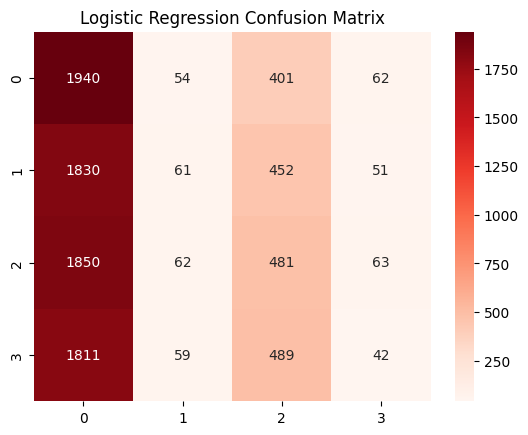

In [70]:
lr_final = LogisticRegression(max_iter=1000, random_state=42)
lr_final.fit(X_train_final_scaled, y_train_final)
y_pred_lr = lr_final.predict(X_test_final)

print("Logistic Regression Classification Report:")
print(classification_report(y_test_final, y_pred_lr))
print("Accuracy:", accuracy_score(y_test_final, y_pred_lr))
sns.heatmap(confusion_matrix(y_test_final, y_pred_lr), annot=True, fmt='d', cmap='Reds')
plt.title("Logistic Regression Confusion Matrix")
plt.show()

KNN

KNN Classification Report:
              precision    recall  f1-score   support

           0       0.27      0.34      0.30      2457
           1       0.25      0.29      0.27      2394
           2       0.25      0.23      0.24      2456
           3       0.24      0.16      0.19      2401

    accuracy                           0.26      9708
   macro avg       0.25      0.25      0.25      9708
weighted avg       0.25      0.26      0.25      9708

Accuracy: 0.2552533992583436


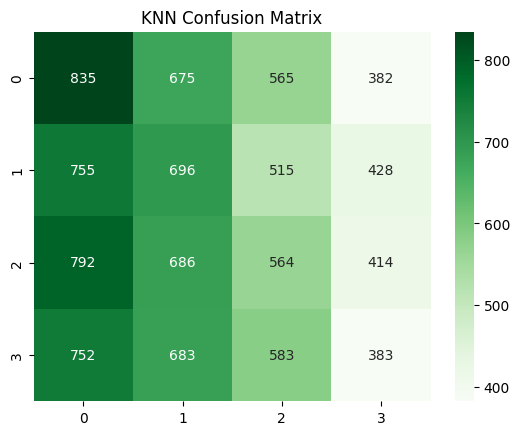

In [71]:
knn_final = KNeighborsClassifier(n_neighbors=5)
knn_final.fit(X_train_final_scaled, y_train_final)
y_pred_knn = knn_final.predict(X_test_final_scaled)

print("KNN Classification Report:")
print(classification_report(y_test_final, y_pred_knn))
print("Accuracy:", accuracy_score(y_test_final, y_pred_knn))
sns.heatmap(confusion_matrix(y_test_final, y_pred_knn), annot=True, fmt='d', cmap='Greens')
plt.title("KNN Confusion Matrix")
plt.show()

SVM

SVM Classification Report:
              precision    recall  f1-score   support

           0       0.25      0.21      0.23      2457
           1       0.25      0.18      0.21      2394
           2       0.25      0.28      0.27      2456
           3       0.24      0.31      0.27      2401

    accuracy                           0.25      9708
   macro avg       0.25      0.25      0.24      9708
weighted avg       0.25      0.25      0.24      9708

Accuracy: 0.24567367119901112


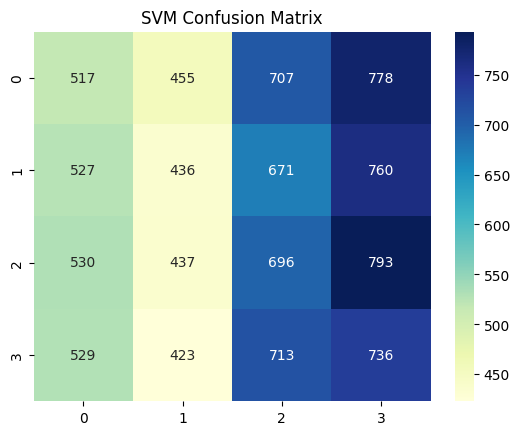

In [72]:
svm_final = SVC(kernel='rbf', random_state=42)
svm_final.fit(X_train_final_scaled, y_train_final)
y_pred_svm = svm_final.predict(X_test_final_scaled)

print("SVM Classification Report:")
print(classification_report(y_test_final, y_pred_svm))
print("Accuracy:", accuracy_score(y_test_final, y_pred_svm))
sns.heatmap(confusion_matrix(y_test_final, y_pred_svm), annot=True, fmt='d', cmap='YlGnBu')
plt.title("SVM Confusion Matrix")
plt.show()

KMEANS

KMeans Classification Report:
              precision    recall  f1-score   support

           0       0.25      0.18      0.21      2457
           1       0.00      0.00      0.00      2394
           2       0.25      0.56      0.35      2456
           3       0.24      0.25      0.25      2401

    accuracy                           0.25      9708
   macro avg       0.19      0.25      0.20      9708
weighted avg       0.19      0.25      0.20      9708

Accuracy: 0.25061804697156986


/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


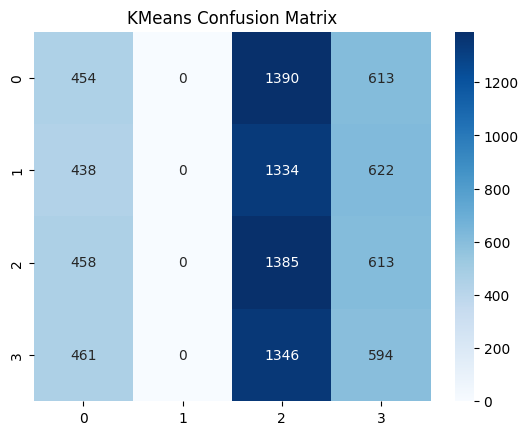

In [73]:
kmeans_final = KMeans(n_clusters=len(y_final.unique()), random_state=42, n_init=10)
kmeans_final.fit(X_train_final_scaled)
y_pred_kmeans_final = kmeans_final.predict(X_test_final_scaled)

labels_map = {}
for i in range(len(np.unique(y_train_final))):
    cluster_indices = (kmeans_final.labels_ == i)
    if np.sum(cluster_indices) > 0:
        most_common = mode(y_train_final[cluster_indices], keepdims=True).mode[0]
        labels_map[i] = most_common

kmeans_labels = [labels_map[label] for label in kmeans_final.predict(X_test_final_scaled)]

print("KMeans Classification Report:")
print(classification_report(y_test_final, kmeans_labels))
print("Accuracy:", accuracy_score(y_test_final, kmeans_labels))
sns.heatmap(confusion_matrix(y_test_final, kmeans_labels), annot=True, fmt='d', cmap='Blues')
plt.title("KMeans Confusion Matrix")
plt.show()